# Method Ablations

We seek Foundation Models properties to see why the compression methods work.

## Ablation 1: Zero-order empirical entropy

## Ablation 2: Blockwise heterogeneity

## Ablation 3: Packed exponents entropy

## Ablation 4: First-order exponent entropy

Compare zero-order entropy with the conditional entropy obtained when the previous exponent is used as context.

,model,tensors,exponent_symbols,transitions,h0_bits_per_exponent,h1_bits_per_exponent,entropy_reduction_bits_per_exponent,entropy_reduction_pct
0,ResNet-18,62,11689512,11689450,2.7449,2.6042,0.1407,5.1248
1,BERT Base Uncased,199,109482240,109482041,2.5984,2.5932,0.0052,0.2019


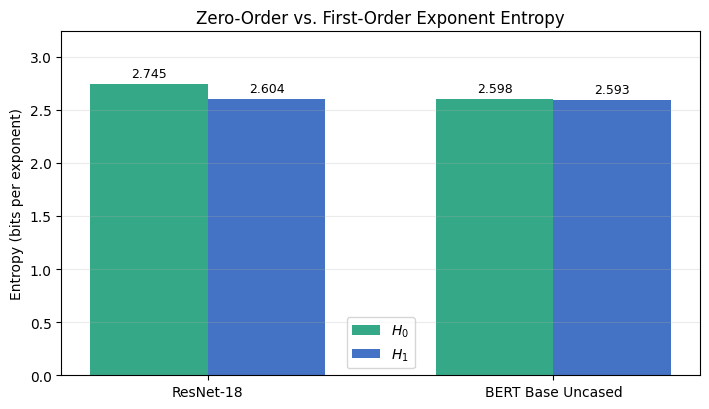

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", message="IProgress not found.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision.models import ResNet18_Weights, resnet18
from transformers import AutoModel, logging as transformers_logging

from neuralzip.ablations import exponent_order_entropies

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
output_dir = root / "examples" / "outputs" / "ablations"
output_dir.mkdir(parents=True, exist_ok=True)

models = {
    "ResNet-18": resnet18(weights=ResNet18_Weights.DEFAULT).to(torch.bfloat16).eval(),
    "BERT Base Uncased": AutoModel.from_pretrained(
        "google-bert/bert-base-uncased", dtype=torch.bfloat16
    ).eval(),
}
order_entropy = pd.DataFrame(
    [{"model": name, **exponent_order_entropies(model)} for name, model in models.items()]
)
order_entropy.to_csv(output_dir / "order_0_vs_order_1_entropy.csv", index=False)
display(order_entropy.round(4))

x = np.arange(len(order_entropy))
width = 0.34
fig, ax = plt.subplots(figsize=(7.2, 4.2))
bars_h0 = ax.bar(
    x - width / 2, order_entropy["h0_bits_per_exponent"], width, label=r"$H_0$", color="#35A987"
)
bars_h1 = ax.bar(
    x + width / 2, order_entropy["h1_bits_per_exponent"], width, label=r"$H_1$", color="#4472C4"
)
ax.bar_label(bars_h0, fmt="%.3f", padding=3, fontsize=9)
ax.bar_label(bars_h1, fmt="%.3f", padding=3, fontsize=9)
ax.set_xticks(x, order_entropy["model"])
ax.set_ylabel("Entropy (bits per exponent)")
ax.set_title("Zero-Order vs. First-Order Exponent Entropy")
ax.grid(axis="y", alpha=0.25)
ax.legend()
ax.set_ylim(0, max(order_entropy["h0_bits_per_exponent"]) * 1.18)
fig.tight_layout()
fig.savefig(output_dir / "order_0_vs_order_1_entropy.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)
